# GELLO / Franka incident: 2026-10-10

Source: `data/recording_20261010_211159_1791637919729.h5`.
This notebook and its companion Python script read the source without modifying it or sending hardware commands.

- 3,288 target samples and 7,415 measured-state samples. Timestamp alignment uses recorder receive nanoseconds in Asia/Shanghai; float32 command `sys_time` is too coarse for this analysis.
- Joint 3 target is outside Panda limits in every sample. Subtracting 2π places every recorded target within limits. This is an offline calibration hypothesis; a known physical reference pose is still required.
- Joint 1 shows no 2π discontinuity in the recorded samples. At the first motion episode its target gap was +41.47°, and at the last episode it was −78.36°. The observed rotation in those episodes approaches the recorded absolute target.
- The recording has no `trigger` or `franka/state_machine`, no raw servo encoder measurements, and no known calibration reference pose. It cannot prove F2 timings or the physical sign/zero calibration of Joint 1. Other movement episodes must not be automatically attributed to GELLO follow mode.
- The file has stale HDF5 end-of-address metadata. Seventeen unfiltered chunks were recovered from stored byte offsets, bounded by physical file size. Raw decoding was compared exactly with h5py for 173 readable chunks. Tail values are recovered evidence, without an independent checksum.

The companion script contains the chunk extraction, finite/type/timestamp/sequence/range checks, motion segmentation, and plotting code. Motion episodes are measured-velocity segments, not state-machine transitions.


In [1]:
from pathlib import Path
import importlib.util
import json

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "proto/franka.proto").is_file())
spec = importlib.util.spec_from_file_location("diagnostics", root / "analysis/gello_franka_recording_diagnostics.py")
diagnostics = importlib.util.module_from_spec(spec)
spec.loader.exec_module(diagnostics)
summary, arrays = diagnostics.analyze()
evidence = diagnostics.motion_evidence(arrays)
figure_path = diagnostics.plot_diagnostics(arrays)
print("Comparable raw chunks validated:", sum(v["validated_chunks"] for a in summary["audit"].values() for v in a.values()))
print("Chunks recovered beyond HDF5 EOA:", sum(len(v["recovered_chunks"]) for a in summary["audit"].values() for v in a.values()))
for episode in (evidence["episodes"][0], evidence["episodes"][-1]):
    print(json.dumps(episode, indent=2))


franka_command {"samples": 3288, "first_time": "2026-10-10T21:14:28.381+08:00", "last_time": "2026-10-10T21:16:39.321+08:00", "outside_limits_count": [0, 0, 3288, 0, 0, 0, 0], "first_q": [0.36662140830466816, -0.0337475773334841, 5.984059053541886, -1.8223691760081417, -0.14419419406125034, 2.0125827937059615, 0.06902913545485401, 0.0], "min_q": [-2.6016314162540475, -0.7378447589728399, 4.261398631814273, -2.552544031041707, -0.7086991238037487, 0.9786797426711924, -0.8130067496177866, 0.0], "max_q": [1.1612234563834105, 0.49547579448706225, 6.525554271665518, -1.468019614144617, 0.4893398713201797, 2.7933788613416732, 1.1320778213982439, 0.42805979957216916]}
franka_state {"samples": 7415, "first_time": "2026-10-10T21:11:18.302+08:00", "last_time": "2026-10-10T21:16:39.183+08:00", "outside_limits_count": [0, 0, 203, 0, 0, 0, 0], "first_q": [-0.3281593550414874, -0.885589740125759, 0.132909229082577, -2.7465866956374865, 0.18797793459892545, 1.9525843319632887, 0.5001180675707283, 0.0

In [2]:
import numpy as np
cmd = arrays["franka_command_joints_position"]
state = arrays["franka_state_joints_position"]
limits = np.array(summary["joint_limits_rad"])
assert cmd.shape == (3288, 8) and state.shape == (7415, 8)
assert all(v["finite"] for a in summary["audit"].values() for v in a.values())
assert np.all(cmd[:, 2] > limits[2, 1])
corrected_j3 = cmd[:, 2] - 2*np.pi
assert np.all((corrected_j3 >= limits[2, 0]) & (corrected_j3 <= limits[2, 1]))
assert np.max(np.abs(np.diff(cmd[:, 0]))) < 0.25
# Independently compare target gap using a scalar calculation and degree conversion.
first = evidence["episodes"][0]
last = evidence["episodes"][-1]
for episode in (first, last):
    c = episode["command_index_at_start"]
    s = episode["state_index_start"]
    gap = float(cmd[c, 0] - state[s, 0]) * 180 / np.pi
    assert abs(gap - episode["initial_target_gap_deg"][0]) < 1e-12
print("J1 first-motion target gap (deg):", first["initial_target_gap_deg"][0])
print("J1 last-motion target gap (deg):", last["initial_target_gap_deg"][0])
print("J3 corrected hypothetical range (rad):", corrected_j3.min(), corrected_j3.max())
print("No commands were published or sent to hardware.")


J1 first-motion target gap (deg): 41.47090970537623
J1 last-motion target gap (deg): -78.35623980009447
J3 corrected hypothetical range (rad): -2.0217866753653135 0.24236896448593193
No commands were published or sent to hardware.


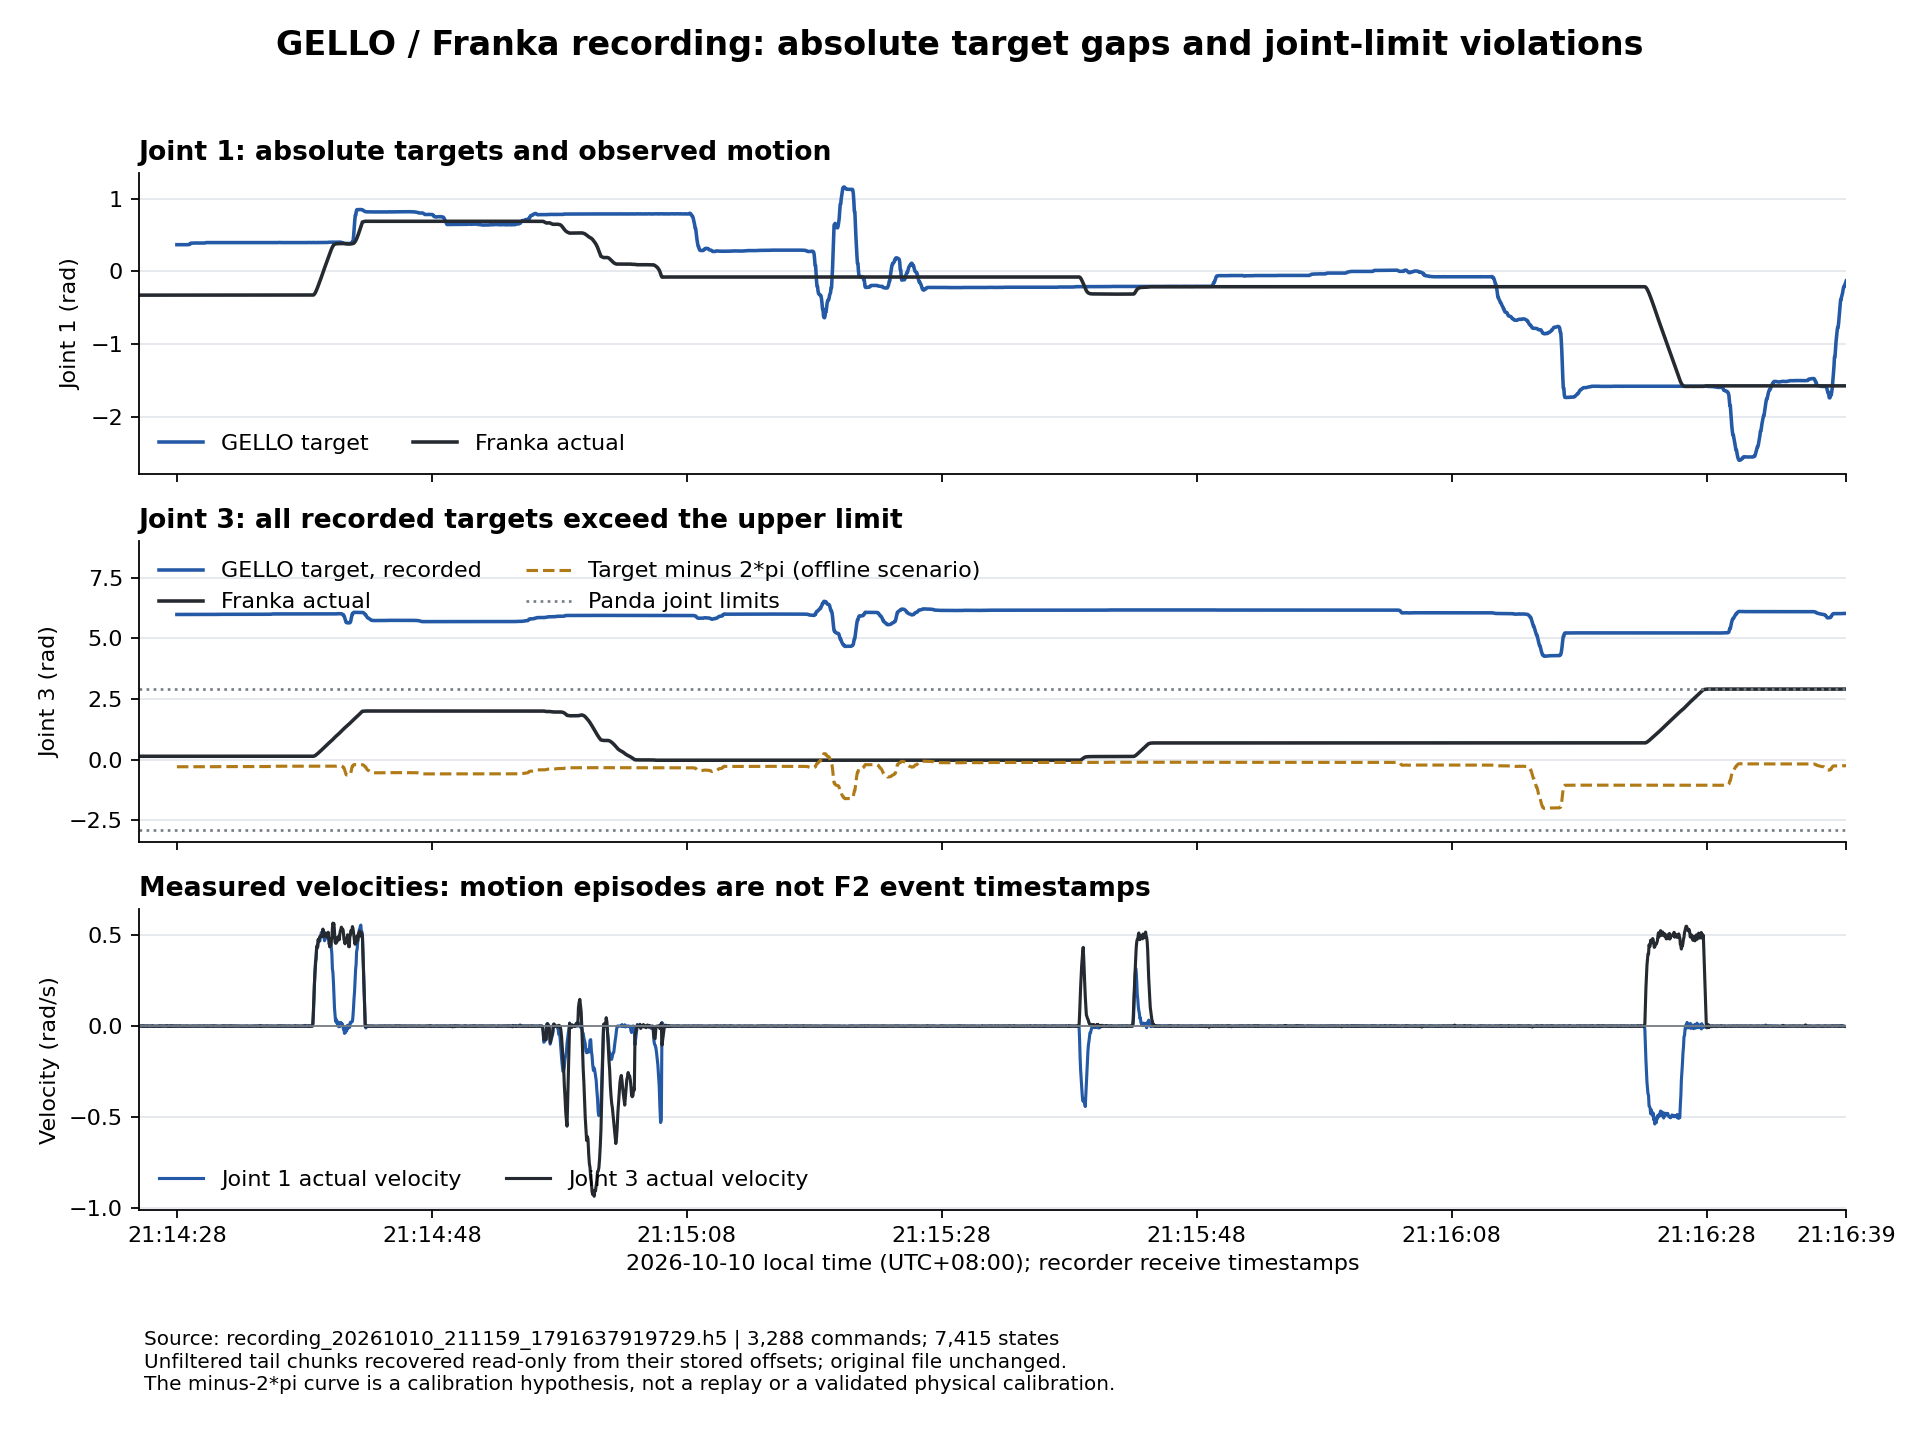

In [3]:
from IPython.display import Image, display
display(Image(filename=str(figure_path)))